# 01 – First look at one time series

**Goal of this notebook:** before modelling 1,782 series (54 stores × 33 product families),
understand **one** of them really well. Patterns we find here tell us which features to build later.

We pick the biggest store (44) and the biggest product family (`GROCERY I`): large numbers mean
less random noise, so the patterns are easier to see.

The four things to look for in any time series:

| Pattern | Question | Example |
|---|---|---|
| **Trend** | Does it go up or down over years? | A store getting more customers |
| **Seasonality** | Does it repeat on a fixed calendar cycle? | Weekends, December |
| **Special events** | Are there one-off jumps or drops? | Holidays, an earthquake |
| **Gaps** | Are dates missing, or are there zeros? | Store closed |

In [1]:
# Make `from src...` work: the notebook runs inside notebooks/, but src/ is one level up.
# Adding the parent folder to Python's search path is the simplest fix for a project this size.
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd

from src.data import load_train

# Charts are saved here so the README can show them.
IMAGES = "../images"

In [2]:
train = load_train()
train.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1782,2013-01-02,1,AUTOMOTIVE,2.0,0
2,3564,2013-01-03,1,AUTOMOTIVE,3.0,0
3,5346,2013-01-04,1,AUTOMOTIVE,3.0,0
4,7128,2013-01-05,1,AUTOMOTIVE,5.0,0


Each row is **one store, one product family, one day**. `sales` is the amount sold that day
(it can be fractional: some products are sold by weight, e.g. kilos of meat).
`onpromotion` is how many items of that family were on promotion that day; we come back to it in step 8.

In [3]:
# Keep one series. store_nbr is a category whose values are numbers (see src/data.py).
# set_index("date") makes the dates the index, which unlocks pandas' time series tools
# (selecting by date ranges like series["2016-04"], resampling, rolling windows).
series = (
    train[(train["store_nbr"] == 44) & (train["family"] == "GROCERY I")]
    .set_index("date")["sales"]
)
print(f"{len(series):,} days, from {series.index.min():%Y-%m-%d} to {series.index.max():%Y-%m-%d}")
series.describe().round(0)

1,684 days, from 2013-01-01 to 2017-08-15


count     1684.0
mean      9730.0
std       3576.0
min          0.0
25%       7271.0
50%       8804.0
75%      11646.0
max      46271.0
Name: sales, dtype: float64

## 1. Gaps: are any days missing?

A daily series from 2013-01-01 to 2017-08-15 should have one row per calendar day.
Missing days matter a lot later: a "sales 7 days ago" feature silently shifts by the wrong
amount if some days are absent. So we check first.

In [4]:
# pd.date_range builds the complete calendar; .difference() lists the dates our series lacks.
all_days = pd.date_range(series.index.min(), series.index.max(), freq="D")
missing = all_days.difference(series.index)
print("Missing days:", list(missing.strftime("%Y-%m-%d")))

# Zeros are different from missing: the row exists, but nothing was sold.
print("Days with zero sales:", list(series[series == 0].index.strftime("%Y-%m-%d")))

Missing days: ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']
Days with zero sales: ['2013-01-01', '2014-01-01', '2015-01-01', '2016-01-01', '2017-01-01']


**What we found:**
- **Christmas Day (25 December) is missing in every year.** The stores are closed and the rows were
  simply left out of the file. This is true for all stores, not just this one.
- **New Year's Day (1 January) has zero sales** every year: this store is closed, but here the row exists.
  (Not every store closes: across the whole file, 147 rows have sales on 1 January.)

**Why it matters:** before building lag features (step 6), we will add the missing Christmas rows back,
so that "7 rows ago" always means "7 days ago". We will also treat 1 January as a known closed day
rather than as a real drop in demand.

*Looking back:* step 7b did this for every closed day, not only 1 January: a day on which a whole store sold nothing is treated as unknown (`closed_store_days` in `src/lags.py`).

## 2. Trend: the big picture

Daily sales jump around a lot, which hides the long-term direction. A **rolling mean** averages
each day with the days before it, smoothing out the noise. We use 28 days: exactly 4 weeks, so every
window contains each weekday the same number of times and the weekly pattern cancels out.

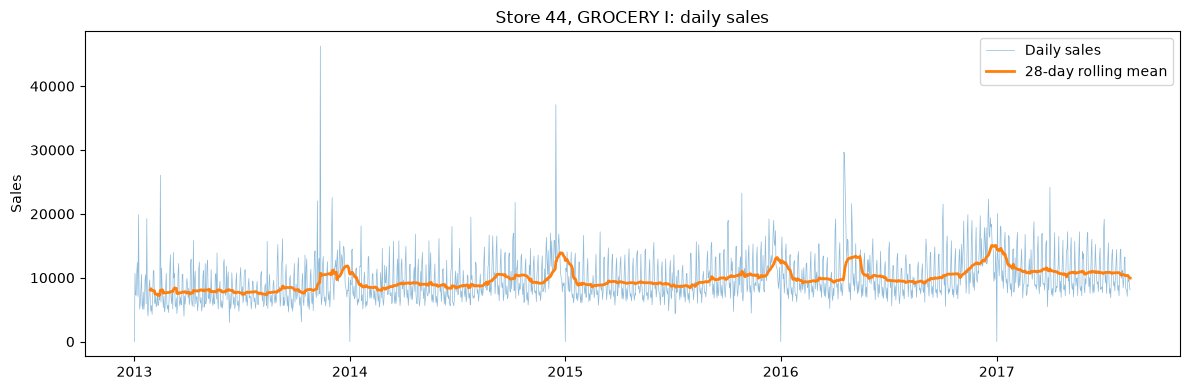

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(series.index, series, linewidth=0.5, alpha=0.5, label="Daily sales")
ax.plot(series.index, series.rolling(28).mean(), linewidth=2, label="28-day rolling mean")
ax.set_title("Store 44, GROCERY I: daily sales")
ax.set_ylabel("Sales")
ax.legend()
fig.tight_layout()
fig.savefig(f"{IMAGES}/one_series.png", dpi=120)
plt.show()

In [6]:
# Average daily sales per year. We use the average, not the total, because 2017 stops in August:
# a total would make 2017 look smaller just because it has fewer days.
yearly = series.groupby(series.index.year).mean().round(0)
print(yearly)
print(f"Growth 2013 -> 2017: {yearly.iloc[-1] / yearly.iloc[0] - 1:.0%}")

date
2013     8398.0
2014     9474.0
2015     9668.0
2016    10677.0
2017    10857.0
Name: sales, dtype: float64
Growth 2013 -> 2017: 29%


**What we found:** sales grow steadily, roughly 30% from 2013 to 2017, and the spikes are mostly at the
end of each year. In April 2016 the rolling mean jumps for several weeks, which no other spring does; section 5 looks at why. (The single highest day is in late 2013. One-day spikes like that are common around holidays and promotions.)

**Why it matters:** a model trained on 2013 sales levels would forecast too low for 2017.
Recent data is the most relevant, which is one reason forecasters often train on the last year or two only.

## 3. Weekly seasonality

`series.index.day_of_week` gives the weekday as a number, **0 = Monday … 6 = Sunday**.
Grouping by it and averaging shows a typical week.

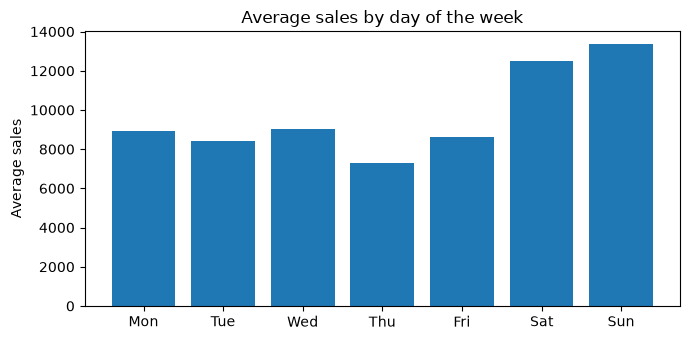

Weekend days sell 53% more than weekdays


In [7]:
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_weekday = series.groupby(series.index.day_of_week).mean()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(weekday_names, by_weekday)
ax.set_title("Average sales by day of the week")
ax.set_ylabel("Average sales")
fig.tight_layout()
fig.savefig(f"{IMAGES}/weekday_pattern.png", dpi=120)
plt.show()

weekend = by_weekday.loc[[5, 6]].mean()
weekdays = by_weekday.loc[[0, 1, 2, 3, 4]].mean()
print(f"Weekend days sell {weekend / weekdays - 1:.0%} more than weekdays")

**What we found:** Saturday and Sunday sell about 50% more than weekdays; Thursday is the quietest day.

**Why it matters:** this is the strongest pattern in the data, and it gives us our first baseline idea
for step 3: *"sales on the same weekday last week"* already knows that Saturdays are busy.
Comparing with *yesterday* would not: it would forecast Saturday from a quiet Friday.

## 4. Yearly seasonality and paydays

Two more calendar cycles to check:
- **Month of the year**: is December special?
- **Day of the month**: the competition's data page says public-sector wages in Ecuador are paid
  on the 15th and on the last day of the month. Do people shop more just after payday?

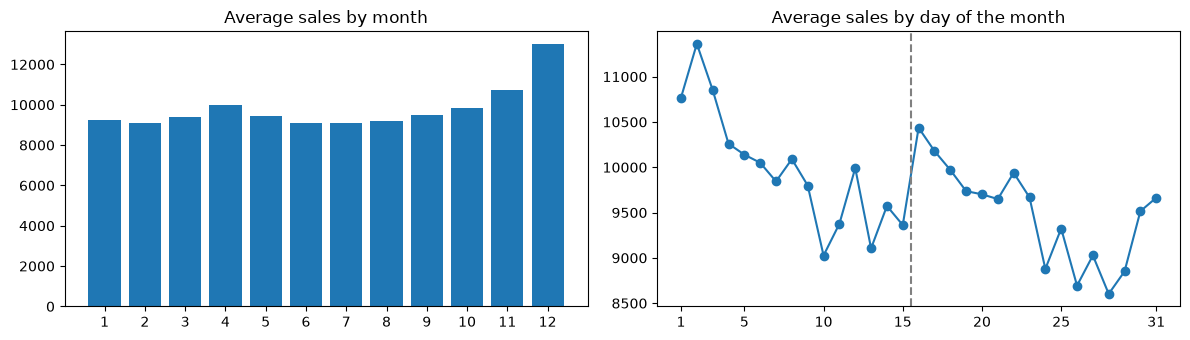

December vs. the other months: +37%
Days 1-3 vs. days 24-29: +24%


In [8]:
by_month = series.groupby(series.index.month).mean()
by_day = series.groupby(series.index.day).mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].bar(by_month.index, by_month)
axes[0].set_title("Average sales by month")
axes[0].set_xticks(range(1, 13))

axes[1].plot(by_day.index, by_day, marker="o")
axes[1].set_title("Average sales by day of the month")
axes[1].axvline(15.5, color="grey", linestyle="--")  # just after the mid-month payday
axes[1].set_xticks([1, 5, 10, 15, 20, 25, 31])
fig.tight_layout()
fig.savefig(f"{IMAGES}/month_and_payday.png", dpi=120)
plt.show()

print(f"December vs. the other months: {by_month[12] / by_month.drop(12).mean() - 1:+.0%}")
print(f"Days 1-3 vs. days 24-29: {by_day.loc[1:3].mean() / by_day.loc[24:29].mean() - 1:+.0%}")

**What we found:**
- **December sells about 40% more** than an average month (Christmas shopping). November starts rising too.
- **A payday effect, but a small one:** the first days of the month sell about 25% more than the end of the
  month, and there is a small bump on the 16th, the day after the mid-month payday.

**Why it matters:** in step 5 we will give the model calendar features: day of week, month,
day of month, and "days since payday". The weekday effect is much bigger than the payday effect,
so we should not expect miracles from the payday features.

*A note of caution:* these are averages over only 4–5 years. December has just 4 Decembers behind it,
so its average is less certain than the weekday averages, which each use about 240 days.

## 5. A special event: the April 2016 earthquake

The trend chart showed an unusual jump in April 2016. On **16 April 2016 (a Saturday) a magnitude 7.8
earthquake struck Ecuador**. The competition's data page mentions it: people donated water and food,
and grocery sales jumped for several weeks. Let's zoom in using date slicing: with a date index,
`series["2016-04-01":"2016-05-15"]` selects that period directly.

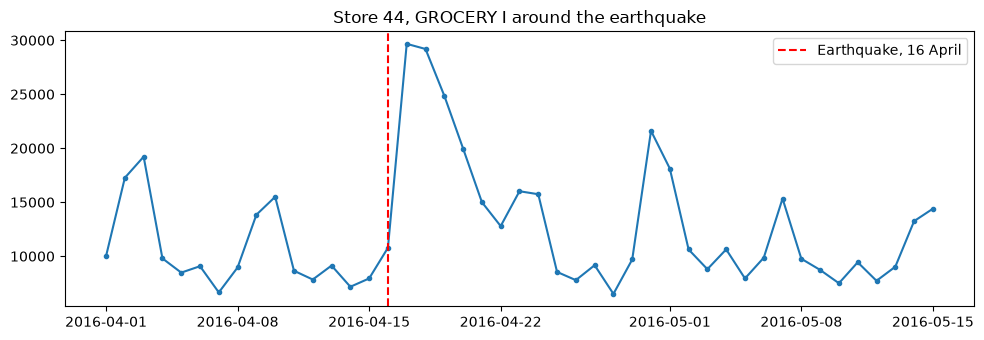

Normal level (March to mid-April): 9,756
17-19 April:                       27,908


In [9]:
window = series["2016-04-01":"2016-05-15"]

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(window.index, window, marker="o", markersize=3)
ax.axvline(pd.Timestamp("2016-04-16"), color="red", linestyle="--", label="Earthquake, 16 April")
ax.set_title("Store 44, GROCERY I around the earthquake")
ax.legend()
fig.tight_layout()
fig.savefig(f"{IMAGES}/earthquake.png", dpi=120)
plt.show()

normal = series["2016-03-01":"2016-04-15"].mean()
print(f"Normal level (March to mid-April): {normal:,.0f}")
print(f"17-19 April:                       {series['2016-04-17':'2016-04-19'].mean():,.0f}")

**What we found:** for three days after the earthquake, sales were about 3 times their normal level,
then they slowly returned to normal over roughly two weeks.

**Why it matters:** this will never repeat on a calendar, so no feature can predict it. But it can
**mislead** the model: lag features from late April 2016 look like a booming demand.
Common options are to drop those weeks from training or to flag them. We will decide in step 7, and
remember to check whether it makes a difference rather than guessing.

*Looking back:* step 7 (notebook 06) checked it. Dropping those weeks from training changed the backtest by less than 0.001, so the data stays.

## 6. Is this series typical? A quick look at all 1,782

We studied the biggest, smoothest series. Many others look very different. A quick check:
how many rows are zero?

In [10]:
print(f"Rows with zero sales: {(train['sales'] == 0).mean():.0%}")

# For each (store, family) series: what share of its days are zero?
# observed=True: only group by combinations that exist (needed because the columns are categories).
zero_share = train.groupby(["store_nbr", "family"], observed=True)["sales"].apply(lambda s: (s == 0).mean())
print(f"Series that are zero on more than half of their days: {(zero_share > 0.5).mean():.0%}")

# The families with the most zeros
zero_share.groupby(level="family", observed=True).mean().sort_values(ascending=False).head(5).round(2)

Rows with zero sales: 31%


Series that are zero on more than half of their days: 25%


family
BOOKS                         0.97
BABY CARE                     0.94
SCHOOL AND OFFICE SUPPLIES    0.74
HOME APPLIANCES               0.74
LADIESWEAR                    0.60
Name: sales, dtype: float64

**What we found:** about 31% of all rows are zero, and a quarter of the series are zero on most days.
Some families (like `BOOKS` or `BABY CARE`) barely sell at all, and some stores sell nothing in a
family because they don't stock it.

**Why it matters:**
- A rule like "if a series has been zero for weeks, forecast zero" can be both simple and very effective.
- The competition metric (RMSLE, step 3) looks at *relative* errors, so being off by 5 on a series that
  sells 2 counts more than being off by 5 on a series that sells 10,000. Small series matter.

## Summary

| Finding | What we will do with it |
|---|---|
| Christmas rows are missing, 1 January is zero | Fill in the missing dates before making lags (step 6) |
| Sales grow ~30% over 4.5 years | Favour recent data; check the trend when validating (step 4) |
| Weekends sell ~50% more | First baseline: same weekday last week (step 3); weekday feature (step 5) |
| December +40%, small payday effect | Month and payday features (step 5) |
| April 2016 earthquake: sales ×3 for days | Decide whether to drop or flag those weeks (step 7: no difference, kept) |
| 31% of rows are zero | A `zero_days_28` feature lets the model learn it (step 6), instead of a separate rule |

**Next step (step 3):** simple baselines. Before any model, how well can we do with rules like
"same as last week"? That number is the bar every model must clear.